# Padronização da Direção do Ataque

Este notebook processa os arquivos limpos (`_limpo.parquet`) para padronizar a direção do jogo, garantindo que as equipes sempre ataquem na mesma direção (da esquerda para a direita, no sentido positivo do eixo X).

**Processo:**
1.  Para cada jogo, carrega os dados de jogadores e metadados da pasta `parquets_limpos`.
2.  Com base na coluna `period`, identifica os dados do segundo tempo (`period == 2`).
3.  **Inverte todas as coordenadas e vetores relevantes** (`x`, `y`, `ball_x`, `ball_y`, `vx`, `vy`, `ax`, `ay`) nos frames do segundo tempo.
4.  Salva os novos DataFrames padronizados (`_standard.parquet`) em uma nova pasta.

In [6]:
import pandas as pd
import os
import re
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
sns.set_style("whitegrid")
pd.set_option('display.max_columns', 50)

In [7]:
def padronizar_jogo(match_id: str, pasta_entrada: str, pasta_saida: str) -> bool:
    """
    Carrega os dados de um jogo, padroniza a direção do ataque e salva os novos arquivos.
    Esta versão foi corrigida para usar as colunas exatas disponíveis nos arquivos.

    Args:
        match_id (str): O ID do jogo a ser processado.
        pasta_entrada (str): Pasta contendo os arquivos `_limpo.parquet`.
        pasta_saida (str): Pasta onde os arquivos `_standard.parquet` serão salvos.

    Returns:
        bool: True se bem-sucedido, False caso contrário.
    """
    try:
        # ---- Carregar os arquivos limpos ----
        caminho_players = os.path.join(pasta_entrada, f'{match_id}_limpo.parquet')
        
        df_players = pd.read_parquet(caminho_players)

        # ---- Identificar frames para inverter usando a coluna 'period' do próprio df_players ----
        mascara_para_inverter = df_players['period'] == 2
        
        if mascara_para_inverter.any():
            # ---- Definir todas as colunas espaciais e vetoriais para inverter ----
            cols_para_inverter = ['x', 'y', 'ball_x', 'ball_y', 'vx', 'vy', 'ax', 'ay']
            
            # Garante que só tentaremos inverter colunas que realmente existem no DataFrame
            cols_existentes = [col for col in cols_para_inverter if col in df_players.columns]
            
            # Aplica a inversão (multiplica por -1) nas colunas existentes para as linhas da máscara
            df_players.loc[mascara_para_inverter, cols_existentes] *= -1

        # ---- Salvar os arquivos padronizados ----
        caminho_saida_players = os.path.join(pasta_saida, f'{match_id}_standard.parquet')
        
        df_players.to_parquet(caminho_saida_players, index=False)
        
        return True

    except FileNotFoundError:
        print(f"Erro: Arquivos para o jogo {match_id} não encontrados em '{pasta_entrada}'. Pulando.")
        return False
    except Exception as e:
        print(f"Erro inesperado ao processar o jogo {match_id}: {e}")
        return False

In [ ]:
# ---- Configuração dos Caminhos ----
pasta_entrada = 'parquets_limpos'
pasta_saida = 'parquets_standardizados'

# Cria a pasta de saída se ela não existir
os.makedirs(pasta_saida, exist_ok=True)
print(f"Lendo de: '{pasta_entrada}'")
print(f"Salvando em: '{pasta_saida}'")

# ---- Identificar todos os IDs de jogos na pasta de entrada ----
padrao = re.compile(r'(\d+)_limpo\.parquet')
todos_arquivos = os.listdir(pasta_entrada)
ids_jogos = sorted(list(set(padrao.match(f).group(1) for f in todos_arquivos if padrao.match(f))))

if not ids_jogos:
    print("\nNenhum arquivo '_limpo.parquet' encontrado.")
else:
    print(f"\nEncontrados {len(ids_jogos)} jogos para padronizar.")
    
    # ---- Loop Principal ----
    sucessos = 0
    falhas = 0
    for match_id in tqdm(ids_jogos, desc="Padronizando jogos"):
        if padronizar_jogo(match_id, pasta_entrada, pasta_saida):
            sucessos += 1
        else:
            falhas += 1
            
    print("\n--- Padronização Concluída ---")
    print(f"Jogos processados com sucesso: {sucessos}")
    print(f"Falhas: {falhas}")

Lendo de: 'tracking\parquets_limpos'
Salvando em: 'tracking\parquets_standardizados'

Encontrados 233 jogos para padronizar.


Padronizando jogos:   0%|          | 0/233 [00:00<?, ?it/s]


--- Padronização Concluída ---
Jogos processados com sucesso: 233
Falhas: 0


### Verificação: Os chutes estão todos para o mesmo lado?
Para verificar se a padronização funcionou, vamos plotar a **posição da bola** no momento de cada chute. Se tudo deu certo, as posições da bola nos chutes do 1º e do 2º tempo devem estar no mesmo lado do campo de ataque.

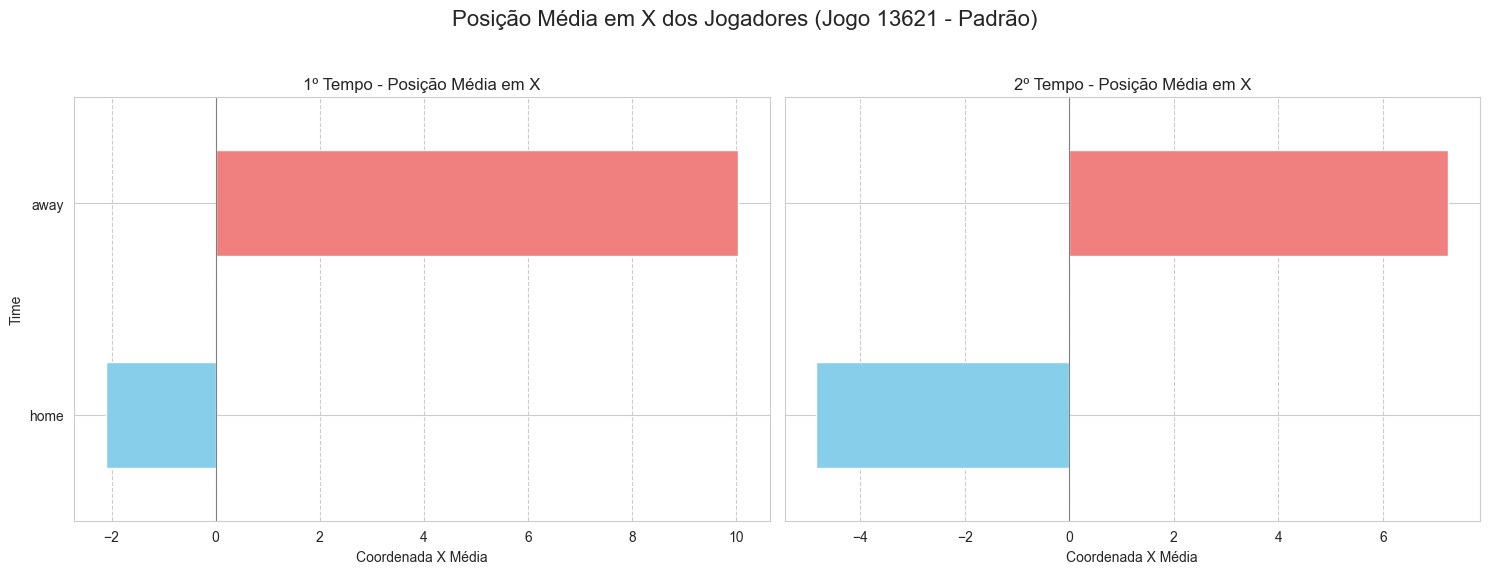


Análise:
Se a padronização funcionou corretamente:
- No 1º Tempo, a posição média em X dos times deve estar mais à esquerda (valores menores de X) indicando o início do ataque para a direita.
- No 2º Tempo, após a possível inversão, a posição média em X dos times também deve estar relativamente à esquerda no INÍCIO do tempo, movendo-se para a direita ao longo do período (o gráfico aqui mostra a média geral do período).


In [23]:
### Verificação: Posição Média dos Jogadores por Time e Período

import numpy as np

if ids_jogos:
    match_id_verificacao = ids_jogos[-1] # Pega o último jogo processado para verificar
    caminho_players_std = os.path.join(pasta_saida, f'{match_id_verificacao}_standard.parquet')

    if os.path.exists(caminho_players_std):
        df_players_verif = pd.read_parquet(caminho_players_std)

        fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
        fig.suptitle(f'Posição Média em X dos Jogadores (Jogo {match_id_verificacao} - Padrão)', fontsize=16)

        for period in [1, 2]:
            df_periodo = df_players_verif[(df_players_verif['period'] == period)]
            if not df_periodo.empty:
                # Calcula a posição média em X para cada time no período
                posicao_media = df_periodo.groupby('team')['x'].mean().sort_values()

                ax = axes[(period - 1)]
                posicao_media.plot(kind='barh', ax=ax, color=['skyblue', 'lightcoral'])
                ax.set_title(f'{period}º Tempo - Posição Média em X')
                ax.set_xlabel('Coordenada X Média')
                ax.set_ylabel('Time')
                ax.grid(axis='x', linestyle='--')
                ax.axvline(0, color='gray', linestyle='-', linewidth=0.8) # Linha central do campo

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajusta o layout para o título
        plt.show()

        print("\nAnálise:")
        print("Se a padronização funcionou corretamente:")
        print("- No 1º Tempo, a posição média em X dos times deve estar mais à esquerda (valores menores de X) indicando o início do ataque para a direita.")
        print("- No 2º Tempo, após a possível inversão, a posição média em X dos times também deve estar relativamente à esquerda no INÍCIO do tempo, movendo-se para a direita ao longo do período (o gráfico aqui mostra a média geral do período).")

    else:
        print("Arquivo de verificação não encontrado.")
else:
    print("Nenhum jogo para verificar.")

Usando o Jogo ID: 13335 para a verificação.


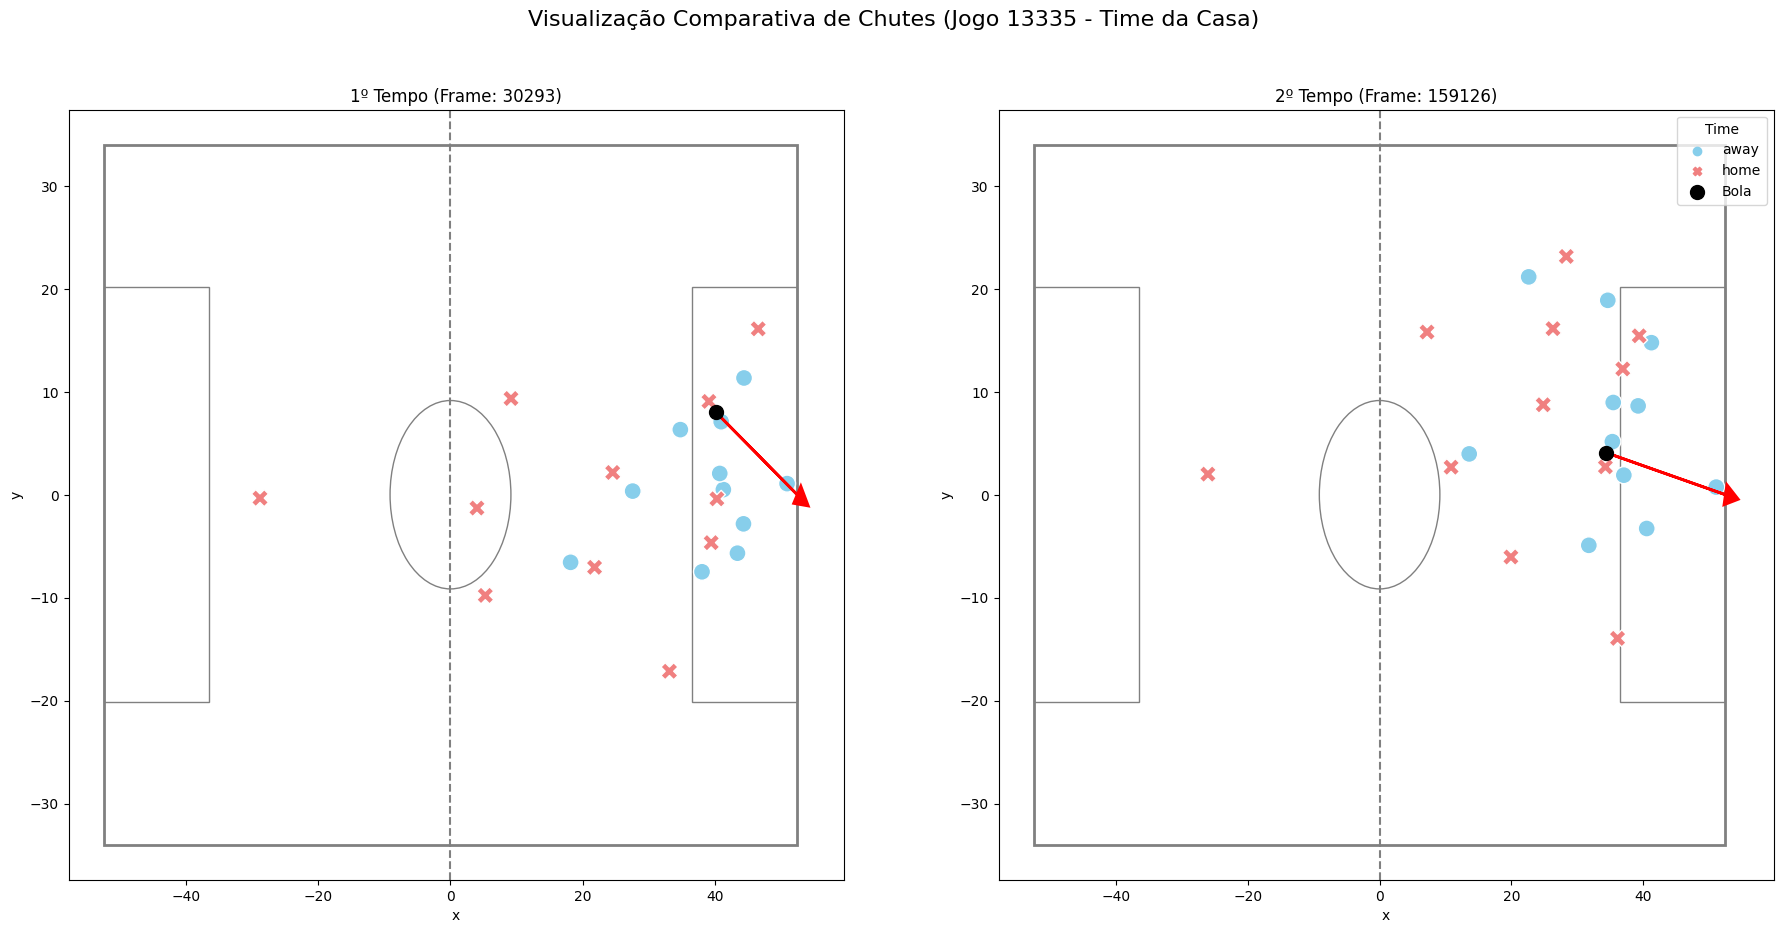

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuração ---
pasta_standard = 'parquets_standardizados'
pasta_limpo = 'parquets_limpos'
# Pega o primeiro ID de jogo da lista para usar como exemplo
try:
    match_id_exemplo = sorted([f.split('_')[0] for f in os.listdir(pasta_standard) if not f.startswith('metadata')])[0]
    print(f"Usando o Jogo ID: {match_id_exemplo} para a verificação.")
except IndexError:
    print("Nenhum arquivo padronizado encontrado na pasta.")
    match_id_exemplo = None

# --- Função Auxiliar para Desenhar o Campo ---
def desenhar_campo(ax):
    """Desenha um campo de futebol simples no eixo fornecido."""
    # Retângulo externo
    ax.add_patch(plt.Rectangle((-52.5, -34), 105, 68, fill=None, edgecolor='gray', lw=2))
    # Linha do meio
    ax.axvline(0, color='gray', linestyle='--')
    # Círculo central
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=None, edgecolor='gray'))
    # Área penal (direita)
    ax.add_patch(plt.Rectangle((36.5, -20.15), 16, 40.3, fill=None, edgecolor='gray'))
    # Área penal (esquerda)
    ax.add_patch(plt.Rectangle((-52.5, -20.15), 16, 40.3, fill=None, edgecolor='gray'))


if match_id_exemplo:
    # --- Carregar Dados Padronizados ---
    caminho_meta = os.path.join(pasta_limpo, f'metadata_{match_id_exemplo}_limpo.parquet')
    caminho_players = os.path.join(pasta_standard, f'{match_id_exemplo}_standard.parquet')
    
    df_meta = pd.read_parquet(caminho_meta)
    df_players = pd.read_parquet(caminho_players)
    
    # --- Encontrar os Chutes ---
    home_team_id = df_meta['event_team_id'].dropna().iloc[0]
    
    chutes_p1 = df_meta[(df_meta['period'] == 1) & (df_meta['possession_type'] == 'Frame_PossessionEventType.SHOT') & (df_meta['event_team_id'] == home_team_id)]
    chutes_p2 = df_meta[(df_meta['period'] == 2) & (df_meta['possession_type'] == 'Frame_PossessionEventType.SHOT') & (df_meta['event_team_id'] == home_team_id)]

    if not chutes_p1.empty and not chutes_p2.empty:
        # Pega o primeiro chute de cada tempo como exemplo
        info_chute_p1 = chutes_p1.iloc[0]
        info_chute_p2 = chutes_p2.iloc[0]
        
        frame_chute_p1 = info_chute_p1['frame_id']
        frame_chute_p2 = info_chute_p2['frame_id']

        # Filtra os dados de tracking para os frames dos chutes
        df_frame_p1 = df_players[df_players['frame_id'] == frame_chute_p1]
        df_frame_p2 = df_players[df_players['frame_id'] == frame_chute_p2]

        # --- Visualização ---
        fig, axes = plt.subplots(1, 2, figsize=(22, 10))
        fig.suptitle(f'Visualização Comparativa de Chutes (Jogo {match_id_exemplo} - Time da Casa)', fontsize=16)

        # Gol de ataque padrão (à direita)
        posicao_gol = (52.5, 0)

        # Plot para o 1º Tempo
        ax1 = axes[0]
        desenhar_campo(ax1)
        sns.scatterplot(data=df_frame_p1, x='x', y='y', hue='team', s=150, palette=['skyblue', 'lightcoral'], ax=ax1, style='team')
        bola_p1 = df_frame_p1.iloc[0] # Posição da bola
        ax1.scatter(bola_p1['ball_x'], bola_p1['ball_y'], color='black', s=100, label='Bola', zorder=5)
        # Seta indicando a direção do chute
        ax1.arrow(bola_p1['ball_x'], bola_p1['ball_y'], posicao_gol[0] - bola_p1['ball_x'], posicao_gol[1] - bola_p1['ball_y'], 
                  head_width=2, head_length=2, fc='red', ec='red', lw=2, zorder=4)
        ax1.set_title(f"1º Tempo (Frame: {frame_chute_p1})")
        ax1.legend().set_visible(False)

        # Plot para o 2º Tempo
        ax2 = axes[1]
        desenhar_campo(ax2)
        sns.scatterplot(data=df_frame_p2, x='x', y='y', hue='team', s=150, palette=['skyblue', 'lightcoral'], ax=ax2, style='team')
        bola_p2 = df_frame_p2.iloc[0] # Posição da bola
        ax2.scatter(bola_p2['ball_x'], bola_p2['ball_y'], color='black', s=100, label='Bola', zorder=5)
        # Seta indicando a direção do chute
        ax2.arrow(bola_p2['ball_x'], bola_p2['ball_y'], posicao_gol[0] - bola_p2['ball_x'], posicao_gol[1] - bola_p2['ball_y'], 
                  head_width=2, head_length=2, fc='red', ec='red', lw=2, zorder=4)
        ax2.set_title(f"2º Tempo (Frame: {frame_chute_p2})")
        ax2.legend(title='Time')
        
        plt.show()
    else:
        print("Não foram encontrados chutes do time da casa em ambos os períodos para este jogo.")